# 📈 Análise do Comportamento de uma Carteira de Ações (2015–2022)

**Autor:** Rafael R. Silva · **Metodologia:** CRISP-DM · **Tipo de problema:** análise financeira descritiva (sem modelo preditivo)

> **Resumo:** analisamos 8 anos de preços de 5 ações da B3 (GOL, CVC, WEG, Magazine Luiza e Totvs) para responder se uma carteira com essas empresas teria rendido mais que o **BOVA11** (fundo que replica o Ibovespa), quanto, e **por quê**.

---

### 📑 Sumário
- **FASE 01:** Entendimento do Negócio
- **FASE 02:** Preparação dos Dados
- **FASE 03:** Cálculo dos Indicadores e Montagem da Carteira
- **FASE 04:** Avaliação
- **FASE 05:** Implantação
- **Insights**, **Próximos Passos** e **Interface com Streamlit**

> ℹ️ **Sobre esta versão (v2):** estrutura CRISP-DM e correção do cálculo do retorno anual em relação à versão original (mantida no repositório para mostrar a evolução). A versão original anualizava a **média dos retornos diários** (× 246), o que superestima o retorno de ações voláteis: a GOL, que **perdeu 51%** no período, aparecia com "+19,6% ao ano". A v2 usa o **CAGR** (crescimento anual composto) e acrescenta **dividendos**, comparação com o **CDI**, **Índice de Sharpe**, **rebalanceamento anual**, **janelas de 3 anos** e **testes automatizados** das funções. Executado com Python 3.13 e pandas 3.0.

# FASE 01: ENTENDIMENTO DO NEGÓCIO

## 🏢 Contexto

Quem investe em ações precisa saber se as suas escolhas estão **valendo a pena**. A forma mais comum de medir isso é comparar a carteira com o **índice do mercado** (Ibovespa): se a carteira rende menos que o índice, seria mais simples e barato comprar um fundo que replica o índice, como o **BOVA11**.

Neste estudo analisamos uma carteira com **5 ações de setores diferentes** entre **2015 e 2022**, um período que inclui a recessão de 2015–2016 e a pandemia de 2020.

| Ação | Empresa (setor) |
|---|---|
| **GOL** | Gol Linhas Aéreas (aviação) |
| **CVC** | CVC Brasil (turismo) |
| **WEGE** | WEG (máquinas e equipamentos elétricos) |
| **MGLU** | Magazine Luiza (varejo) |
| **TOTS** | Totvs (software) |
| **BOVA** | BOVA11: fundo que replica o Ibovespa (**referência**) |

**Fonte dos dados:** Yahoo Finance (biblioteca `yfinance`).

## 🎯 Objetivo

Medir o desempenho de cada ação e da carteira no período e compará-los com o mercado.

> **Pergunta de negócio:** *Uma carteira com essas 5 ações, com o mesmo valor investido em cada uma, teria rendido mais do que investir no BOVA11? Quanto, e de onde veio o resultado?*

**Stakeholder:** gerente do departamento financeiro / investidor pessoa física.

## 🧩 Formato da solução

| Item | Definição |
|---|---|
| **Granularidade** | Preço de fechamento diário de cada ação (um registro por pregão) |
| **Tipo de problema** | Análise descritiva de desempenho histórico. **Não há modelo preditivo**: o objetivo é medir e explicar o passado |
| **Indicadores** | Retorno total, retorno por ano, retorno logarítmico, **CAGR** (crescimento anual composto) e maior queda |
| **Entrega** | Relatório (notebook + README), tabela de indicadores e um **app Streamlit** para simular carteiras |

## 🗺️ Planejamento da solução (CRISP-DM)

| Fase | O que será feito |
|---|---|
| **01. Entendimento do negócio** | Definir a pergunta e os indicadores |
| **02. Preparação dos dados** | Coletar os preços, conferir a qualidade, explorar com 6 hipóteses e criar os retornos diários |
| **03. Indicadores e carteira** | Calcular os retornos, comparar formas de anualizar e montar a carteira |
| **04. Avaliação** | Comparar carteira x BOVA11 e descobrir quais ações explicam o resultado |
| **05. Implantação** | Salvar os indicadores e simular investimentos (app Streamlit) |

> 💡 O roteiro CRISP-DM foi pensado para projetos de Machine Learning. Como este projeto é uma **análise financeira**, a Fase 03 foi adaptada para o **cálculo dos indicadores**, e as etapas exclusivas de modelos (separação treino/teste, balanceamento, limiar e calibração) aparecem com a nota **"Não se aplica"** e o motivo.

# FASE 02: PREPARAÇÃO DOS DADOS

Nesta fase vamos carregar os preços, conferir a qualidade da base, explorar o comportamento das ações e criar as variáveis de retorno.

## 1 - COLETA DOS DADOS

### 1.1. Bibliotecas

In [1]:
import sys

import numpy             as np
import pandas            as pd
import seaborn           as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

#### Funções auxiliares

As funções reutilizáveis ficam na pasta **`src/`** do projeto (também usadas pelo app Streamlit):

| Arquivo | Função | Para que serve |
|---|---|---|
| `src/financas.py` | `baixar_precos` / `carregar_precos` | Baixa os preços do Yahoo Finance / lê o CSV salvo |
| `src/financas.py` | `baixar_cdi` / `carregar_cdi` | Baixa a taxa do CDI do Banco Central / lê o CSV salvo |
| `src/financas.py` | `retorno_total`, `cagr`, `retorno_por_ano`, `volatilidade`, `maior_queda` | Indicadores de desempenho e de risco |
| `src/financas.py` | `indice_sharpe`, `cagr_janelas` | Retorno ajustado ao risco e CAGR em janelas móveis |
| `src/financas.py` | `simular_carteira` | Evolução do valor de uma carteira, **com ou sem rebalanceamento anual** |
| `src/graficos.py` | `plot_linhas`, `plot_barras_retorno`, `plot_retorno_anual_grade` | Gráficos padronizados, salvos em `Imagens/` |

> ✅ As funções de `src/financas.py` têm **testes automatizados** em `tests/test_financas.py` (rodar `pytest` na raiz do projeto). Exemplo: um preço que dobra em 2 anos precisa ter CAGR de ~41,4% ao ano.

In [2]:
sys.path.append('..')  # permite importar a pasta src/ a partir de Notebooks/

from src.financas import (TICKERS, EMPRESAS, baixar_precos, baixar_cdi, carregar_precos, carregar_cdi,
                          anos_no_periodo, retorno_total, cagr, retorno_por_ano, volatilidade, maior_queda,
                          indice_sharpe, cagr_janelas, simular_carteira)
from src.graficos import plot_linhas, plot_barras_retorno, plot_retorno_anual_grade, salvar, CORES

### 1.2. Salvar a base em CSV

Usamos três bases, todas salvas em `Datasets/` para que o resultado seja **reproduzível** (os dados da internet podem mudar ou ficar indisponíveis):

| Arquivo | Fonte | Conteúdo |
|---|---|---|
| `acoes.csv` | Yahoo Finance | Preço de **fechamento** (*Close*), sem dividendos. É a base da versão original |
| `acoes_ajustado.csv` | Yahoo Finance | Preço **ajustado** (*Adj Close*), que considera os dividendos |
| `cdi.csv` | Banco Central (série 12 do SGS) | Taxa diária do **CDI**, referência de renda fixa |

Para baixar tudo de novo, basta mudar `ATUALIZAR_DADOS` para `True`.

> ⚠️ O ticker **GOLL4.SA** não está mais disponível no Yahoo Finance. Por isso, na base ajustada, a GOL usa o preço de fechamento sem ajuste (o mesmo da base original).

In [3]:
ATUALIZAR_DADOS = False   # True baixa as bases novamente (precisa de internet)

if ATUALIZAR_DADOS:
    baixar_precos(TICKERS, coluna='Close').to_csv('../Datasets/acoes.csv')
    baixar_precos(TICKERS, coluna='Adj Close').to_csv('../Datasets/acoes_ajustado.csv')
    baixar_cdi().to_csv('../Datasets/cdi.csv')

precos = carregar_precos('../Datasets/acoes.csv')                    # fechamento (sem dividendos)
precos_ajustados = carregar_precos('../Datasets/acoes_ajustado.csv')  # fechamento ajustado (com dividendos)
cdi = carregar_cdi('../Datasets/cdi.csv', precos.index)              # valor de R$ 1 aplicado no CDI

## 2 - LIMPEZA DOS DADOS

Antes de calcular qualquer retorno, conferimos se a base está completa e coerente.

### 2.1. Leitura dos dados

In [4]:
precos.head()

,GOL,CVC,WEGE,MGLU,TOTS,BOVA
Date,,,,,,
2015-01-02,14.99,15.20,5.923076,0.232812,11.910702,47.259998
2015-01-05,14.85,15.00,5.963461,0.237187,11.544731,46.320000
2015-01-06,15.21,14.80,5.875000,0.234062,10.822770,46.580002
2015-01-07,14.55,14.67,5.807692,0.241875,10.746248,48.150002
2015-01-08,14.27,14.15,5.905769,0.240000,10.995774,48.509998


#### 📖 Dicionário de dados

| Coluna | Descrição |
|---|---|
| `Date` (índice) | Data do pregão. Fins de semana e feriados não aparecem, pois a bolsa não abre |
| `GOL`, `CVC`, `WEGE`, `MGLU`, `TOTS`, `BOVA` | **Preço de fechamento** (em R$) de cada ativo no dia |

> ℹ️ A análise principal usa o **Close** (sem dividendos), a mesma base da versão original, para que as duas versões sejam comparáveis. O efeito dos **dividendos** é medido na Fase 03 (item 4.3) e na avaliação final (Fase 04).

### 2.2. Colunas

In [5]:
print(f'Tickers originais: {list(TICKERS)}')
print(f'Nomes usados:      {precos.columns.tolist()}')

Tickers originais: ['GOLL4.SA', 'CVCB3.SA', 'WEGE3.SA', 'MGLU3.SA', 'TOTS3.SA', 'BOVA11.SA']
Nomes usados:      ['GOL', 'CVC', 'WEGE', 'MGLU', 'TOTS', 'BOVA']


### 2.3. Dimensões de dados

In [6]:
print(f'Pregões: {precos.shape[0]} | Ativos: {precos.shape[1]}')
print(f'Período: {precos.index.min():%d/%m/%Y} a {precos.index.max():%d/%m/%Y} ({anos_no_periodo(precos):.2f} anos)\n')
print('Pregões por ano:')
print(precos.groupby(precos.index.year).size().to_string())

Pregões: 1988 | Ativos: 6
Período: 02/01/2015 a 29/12/2022 (7.99 anos)

Pregões por ano:
Date
2015    246
2016    249
2017    254
2018    246
2019    248
2020    248
2021    247
2022    250


📌 **Nota**
- 🔎 São **1.988 pregões** de **6 ativos**, de 02/01/2015 a 29/12/2022 (**8 anos**).
- 🔎 Cada ano tem entre **246 e 254 pregões**: a bolsa não abre em fins de semana e feriados. A versão original usava 246 como valor fixo; na v2, o crescimento anual é calculado pelos **anos de calendário** (CAGR), sem depender desse número.

### 2.4. Check dados nulos

In [7]:
precos.isnull().sum()

GOL     0
CVC     0
WEGE    0
MGLU    0
TOTS    0
BOVA    0
dtype: int64

✅ Nenhum valor nulo: todos os ativos têm preço em todos os pregões do período.

### 2.5. Estatística descritiva

#### 2.5.1. Separando os tipos de variáveis

In [8]:
precos.dtypes

GOL     float64
CVC     float64
WEGE    float64
MGLU    float64
TOTS    float64
BOVA    float64
dtype: object

Todas as colunas são **numéricas** (preços em R$), e a data está no índice.

#### 2.5.2. Colunas numéricas

In [9]:
precos.describe().round(2)

,GOL,CVC,WEGE,MGLU,TOTS,BOVA
count,1988.00,1988.00,1988.00,1988.00,1988.00,1988.00
mean,15.31,28.04,16.95,6.76,17.89,81.84
std,9.33,16.24,12.48,7.63,9.39,23.96
min,1.16,3.66,4.94,0.03,7.16,36.45
25%,7.90,15.00,6.74,0.41,10.07,60.08
50%,13.93,21.90,9.38,3.91,12.34,82.70
75%,20.99,43.09,30.29,10.28,27.07,103.07
max,43.79,64.80,46.10,27.45,40.60,125.75


📌 **Nota**
- 🔎 Os preços estão em **escalas muito diferentes**: a MGLU variou de R$ 0,03 a R$ 27,45, e o BOVA11 de R$ 36 a R$ 126. Por isso, comparar preços diretamente não faz sentido: é preciso **normalizar** (item 3).
- ⚠️ A versão original dizia que o BOVA11 era o ativo de **maior risco** por ter o maior desvio padrão (23,96). Mas esse é o desvio padrão do **preço**, que é maior simplesmente porque o preço do BOVA11 é maior. O risco se mede pela oscilação dos **retornos** (H6): por esse critério, o BOVA11 é justamente o ativo **menos arriscado** (volatilidade de 26% ao ano).

#### 2.5.3. Colunas Categóricas

> 🚫 **Não se aplica.** A base não tem colunas categóricas: só a data (índice) e os preços.

### 2.6. Verificando outliers

Em preços de ações, um "outlier" não é um erro: são os **dias de movimento extremo**. Para encontrá-los, olhamos os **retornos diários** (variação de um dia para o outro), e não os preços.

In [10]:
variacao_diaria = precos.pct_change()

extremos = pd.DataFrame({
    'Maior queda em 1 dia': variacao_diaria.min(),
    'Data da queda': variacao_diaria.idxmin().dt.strftime('%d/%m/%Y'),
    'Maior alta em 1 dia': variacao_diaria.max(),
    'Data da alta': variacao_diaria.idxmax().dt.strftime('%d/%m/%Y'),
})
extremos.style.format({'Maior queda em 1 dia': '{:.1%}', 'Maior alta em 1 dia': '{:+.1%}'})

,Maior queda em 1 dia,Data da queda,Maior alta em 1 dia,Data da alta
GOL,-36.3%,12/03/2020,+50.3%,01/02/2016
CVC,-34.8%,18/03/2020,+32.4%,26/03/2020
WEGE,-20.6%,16/03/2020,+13.9%,22/07/2020
MGLU,-21.1%,12/03/2020,+37.3%,28/12/2015
TOTS,-15.3%,18/03/2020,+19.8%,25/03/2020
BOVA,-14.6%,12/03/2020,+13.4%,13/03/2020


📌 **Nota**
- 🔎 As **maiores quedas em um único dia** de **todos os ativos** aconteceram entre **12 e 18 de março de 2020**, no início da pandemia (a bolsa chegou a interromper as negociações, o chamado *circuit breaker*). A GOL caiu **36,3%** e a CVC **34,8%** em um único dia.
- 🔎 Logo depois vieram algumas das **maiores altas** (CVC +32,4% e TOTS +19,8% em 25–26/03/2020), mostrando a montanha-russa daquele mês.
- ✅ **Decisão:** manter todos os dias. São movimentos **reais** do mercado, não erros de dado.

### 2.7. Verificando o balanceamento da variável alvo

> 🚫 **Não se aplica.** Não há variável alvo: o projeto não treina um modelo de classificação, e sim mede o desempenho histórico das ações.

## 3 - ANÁLISE EXPLORATÓRIA DOS DADOS

Como as ações têm preços muito diferentes (MGLU começou em R$ 0,23 e BOVA em R$ 47), para compará-las **normalizamos** os preços: todos começam em **1**. Assim, o valor no fim mostra **quantas vezes o dinheiro investido se multiplicou**.

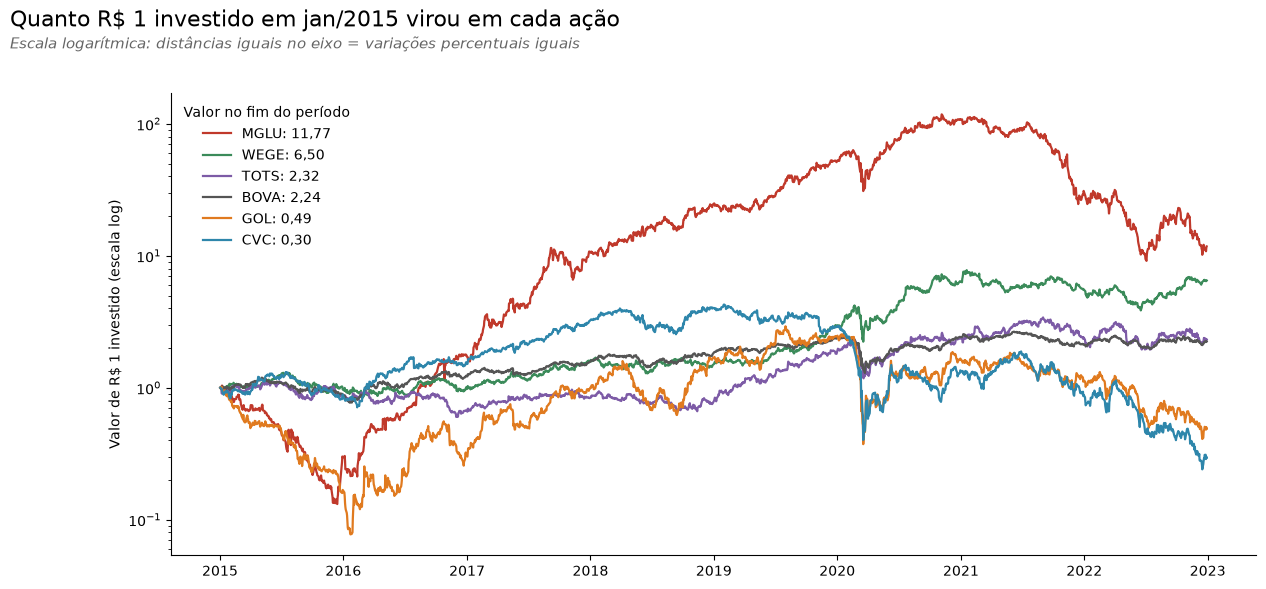

In [11]:
normalizado = precos / precos.iloc[0]

plot_linhas(normalizado, 'Quanto R$ 1 investido em jan/2015 virou em cada ação', 'Crescimento normalizado das acoes',
            ylabel='Valor de R$ 1 investido (escala log)', log=True,
            subtitulo='Escala logarítmica: distâncias iguais no eixo = variações percentuais iguais')

> 💡 **Por que escala logarítmica?** A MGLU chegou a multiplicar o valor por mais de 100, o que "esmagaria" as outras linhas num gráfico comum. Na escala log, sair de 1 para 2 (dobrar) ocupa o mesmo espaço que sair de 50 para 100.

### 3.1. Criação das Hipóteses

| # | Hipótese | Tipo |
|---|---|---|
| H1 | MGLU foi a ação que mais valorizou no período | Individual |
| H2 | As empresas de turismo e aviação (CVC e GOL) foram as mais afetadas pela pandemia | Individual |
| H3 | MGLU subiu muito na pandemia, mas devolveu boa parte do ganho depois | Individual |
| H4 | Uma carteira com as 5 ações (mesmo valor em cada) superou o BOVA11 | Combinada |
| H5 | O resultado da carteira depende principalmente de uma única ação | Combinada |
| H6 | As ações mais arriscadas (que mais oscilam) foram as que mais renderam | Combinada |

### 3.2. Hipóteses Individuais (colunas isoladas)

#### H1 – MGLU foi a ação que mais valorizou no período

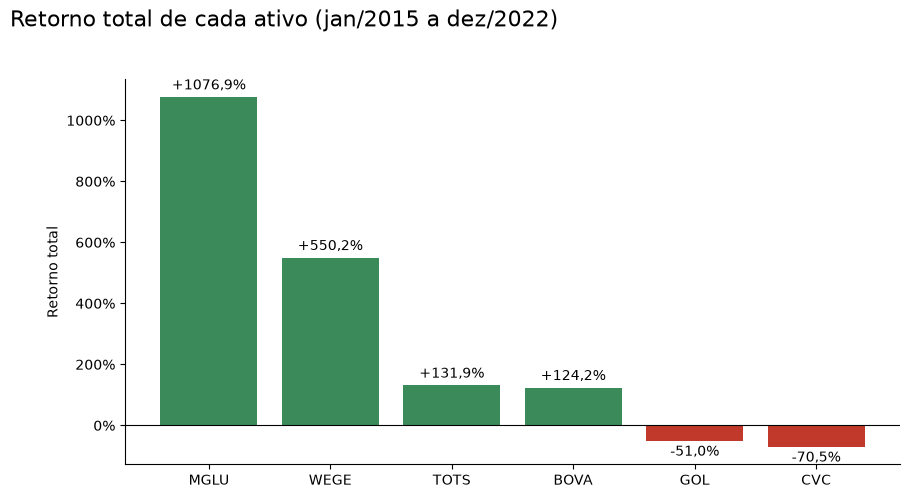

In [12]:
total = retorno_total(precos).sort_values(ascending=False)
plot_barras_retorno(total, 'Retorno total de cada ativo (jan/2015 a dez/2022)', 'Retorno total por ativo',
                    ylabel='Retorno total')

✅ **Verdadeira.** A MGLU subiu **+1.077%** (R$ 1 virou R$ 11,77), seguida pela WEGE (**+550%**). No outro extremo, CVC (**−70%**) e GOL (**−51%**) terminaram valendo menos do que no início. O BOVA11 subiu **+124%**.

#### H2 – CVC e GOL foram as mais afetadas pela pandemia

,GOL,CVC,WEGE,MGLU,TOTS,BOVA
Date,,,,,,
2015,-83.2%,-11.2%,-2.9%,-70.4%,-13.3%,-10.9%
2016,+83.3%,+75.6%,+3.7%,+501.5%,-22.5%,+38.2%
2017,+216.0%,+104.6%,+55.5%,+504.5%,+24.3%,+26.8%
2018,+71.9%,+26.1%,-5.4%,+125.7%,-9.2%,+14.6%
2019,+46.6%,-28.4%,+97.6%,+110.7%,+138.2%,+31.5%
2020,-32.2%,-53.0%,+118.5%,+109.2%,+33.5%,+3.1%
2021,-31.7%,-34.8%,-12.9%,-71.1%,-0.3%,-12.1%
2022,-56.9%,-66.5%,+16.8%,-62.0%,-3.6%,+5.1%


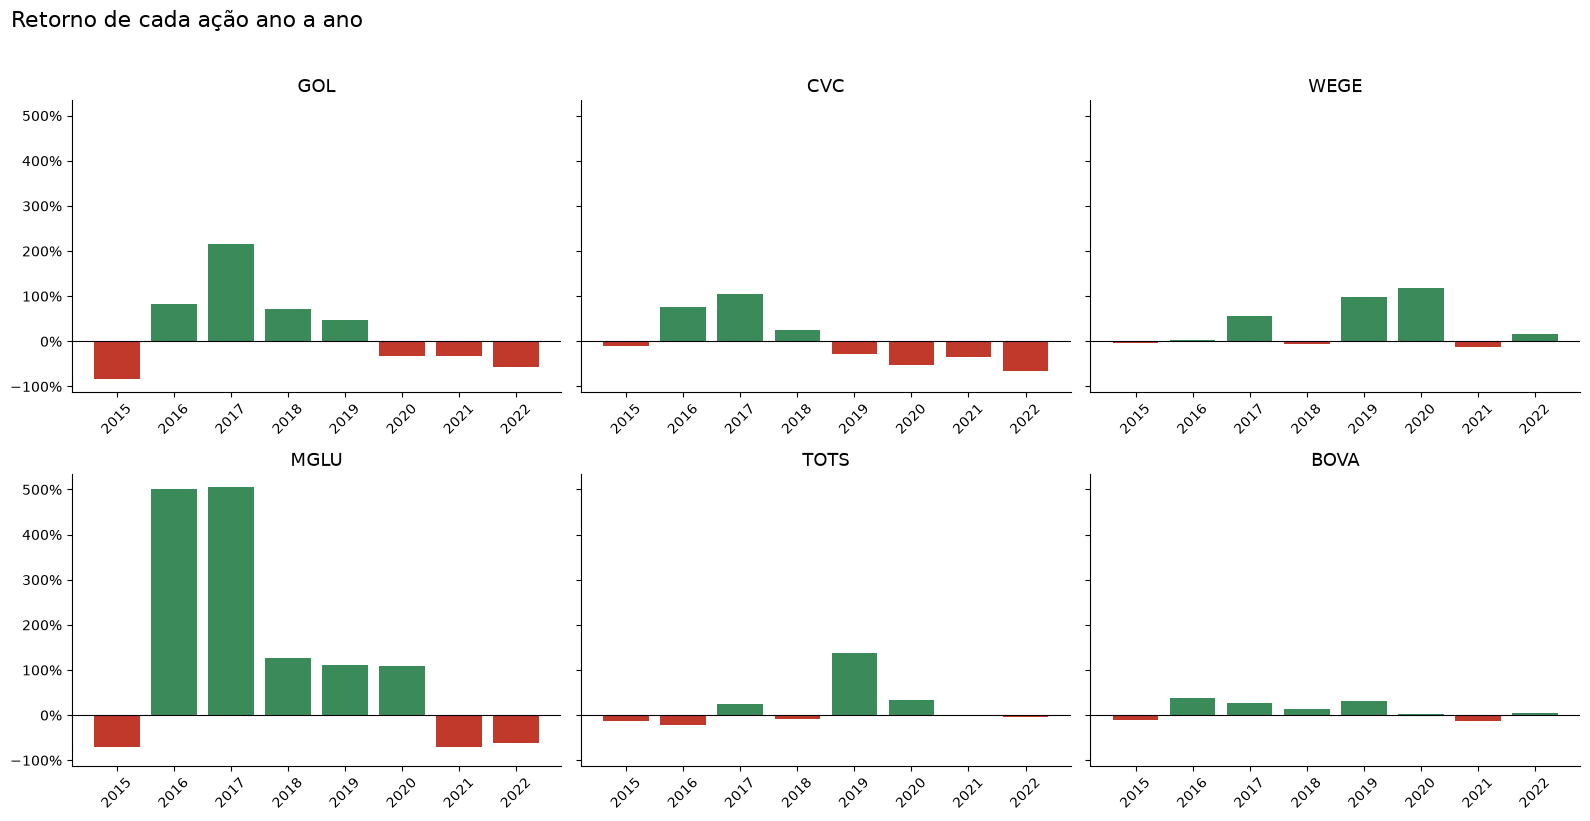

In [13]:
retorno_anual = retorno_por_ano(precos)
display(retorno_anual.style.format('{:+.1%}').background_gradient(cmap='RdYlGn', vmin=-0.8, vmax=0.8))

plot_retorno_anual_grade(retorno_anual, 'Retorno de cada ação ano a ano', 'Retorno por ano')

✅ **Verdadeira.** Em **2020**, a CVC caiu **53%** e a GOL **32%**, enquanto WEGE (+118%) e MGLU (+109%) mais que dobraram. As duas empresas, que dependem de **viagens**, continuaram caindo em 2021 e 2022: a pandemia deixou um efeito longo.

> 💡 O ano a ano também mostra a **instabilidade** das ações individuais: a GOL caiu 83% em 2015 e subiu 216% em 2017, enquanto o BOVA11 nunca variou mais que 38% em um ano.

#### H3 – MGLU subiu muito na pandemia, mas devolveu boa parte do ganho depois

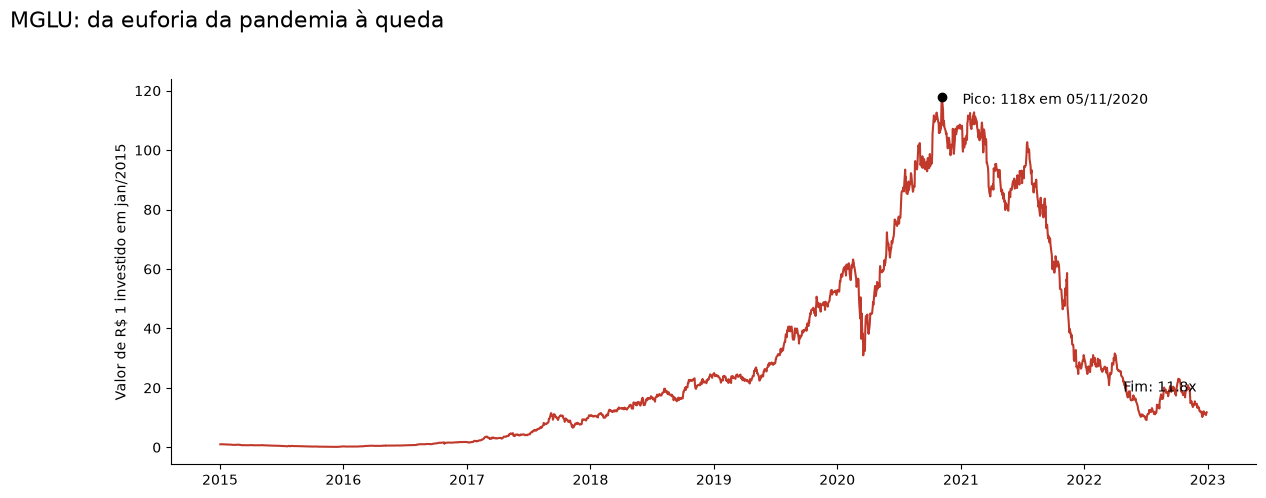

Queda desde o pico: -90.0%


In [14]:
mglu = normalizado['MGLU']
pico = mglu.idxmax()

plt.figure(figsize=(14, 5))
plt.plot(mglu.index, mglu, color=CORES['MGLU'])
plt.scatter(pico, mglu.max(), color='black', zorder=3)
plt.annotate(f'Pico: {mglu.max():.0f}x em {pico:%d/%m/%Y}', (pico, mglu.max()), xytext=(15, -5),
             textcoords='offset points')
plt.annotate(f'Fim: {mglu.iloc[-1]:.1f}x', (mglu.index[-1], mglu.iloc[-1]), xytext=(-60, 15), textcoords='offset points')
plt.ylabel('Valor de R$ 1 investido em jan/2015')
sns.despine()
plt.suptitle('MGLU: da euforia da pandemia à queda', fontsize=16, x=0.01, ha='left', y=1.02)
salvar('MGLU pico e queda')
plt.show()

print(f'Queda desde o pico: {mglu.iloc[-1] / mglu.max() - 1:.1%}')

✅ **Verdadeira.** A MGLU chegou a multiplicar o investimento por **118 vezes** em **05/11/2020**, impulsionada pelo crescimento do comércio online na pandemia. Depois, **caiu 90%** desde o pico e terminou 2022 em **11,8 vezes**. Quem comprou no pico perdeu 90% do valor.

### 3.3. Hipóteses Combinadas (entre colunas)

#### H4 – Uma carteira com as 5 ações superou o BOVA11

Simulamos a compra de **R$ 2.000 em cada uma das 5 ações** (R$ 10.000 no total) no primeiro pregão de 2015, mantendo tudo até o fim de 2022, e comparamos com **R$ 10.000 no BOVA11**.

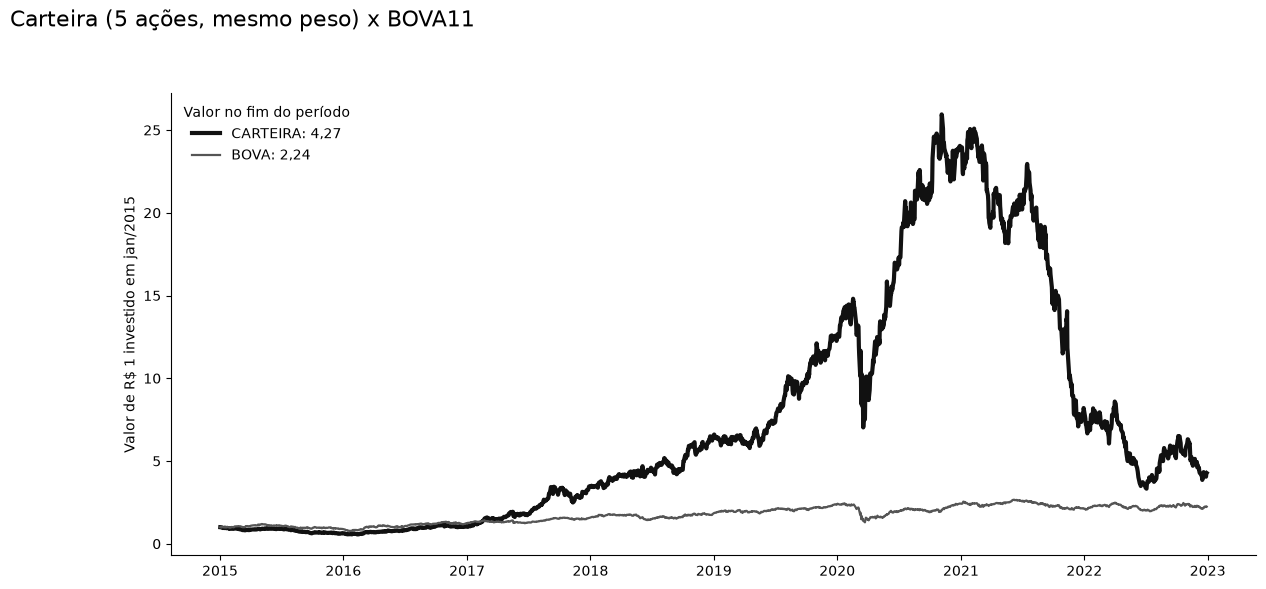

In [15]:
ACOES = ['GOL', 'CVC', 'WEGE', 'MGLU', 'TOTS']
pesos_iguais = {acao: 0.2 for acao in ACOES}

evolucao = pd.DataFrame({
    'CARTEIRA': simular_carteira(precos, pesos_iguais, valor_inicial=1),
    'BOVA': simular_carteira(precos, {'BOVA': 1}, valor_inicial=1),
})
plot_linhas(evolucao, 'Carteira (5 ações, mesmo peso) x BOVA11', 'Carteira x BOVA',
            ylabel='Valor de R$ 1 investido em jan/2015')

✅ **Verdadeira.** R$ 10.000 na carteira viraram **R$ 42.750** (crescimento de **19,9% ao ano**), contra **R$ 22.419** no BOVA11 (**10,6% ao ano**).

⚠️ Mas o gráfico mostra o **outro lado**: a carteira chegou a valer **R$ 259 mil em nov/2020** e caiu para **R$ 33 mil em jul/2022**. O BOVA11 teve uma trajetória muito mais estável.

#### H5 – O resultado da carteira depende principalmente de uma única ação

In [16]:
cenarios = {'Carteira com as 5 ações': ACOES,
            'Carteira sem MGLU': [a for a in ACOES if a != 'MGLU'],
            'Carteira sem MGLU e sem WEGE': [a for a in ACOES if a not in ('MGLU', 'WEGE')]}

cenarios['BOVA11'] = ['BOVA']

linhas = {}
for nome, acoes in cenarios.items():
    valor = simular_carteira(precos, {acao: 1 for acao in acoes})  # mesmo peso para cada ação do cenário
    linhas[nome] = {'Valor final de R$ 10.000': valor.iloc[-1], 'CAGR': cagr(valor)}

comparacao_cenarios = pd.DataFrame(linhas).T
comparacao_cenarios.style.format({'Valor final de R$ 10.000': 'R$ {:,.0f}', 'CAGR': '{:.1%}'})

,Valor final de R$ 10.000,CAGR
Carteira com as 5 ações,"R$ 42,750",19.9%
Carteira sem MGLU,"R$ 24,014",11.6%
Carteira sem MGLU e sem WEGE,"R$ 10,347",0.4%
BOVA11,"R$ 22,419",10.6%


✅ **Verdadeira.**
- 🔎 **Sem a MGLU**, a carteira termina com **R$ 24.014** (11,6% ao ano), praticamente **empatada com o BOVA11** (R$ 22.419).
- 🔎 **Sem MGLU e sem WEGE**, R$ 10.000 viram apenas **R$ 10.347** em 8 anos (0,4% ao ano).
- 💡 Ou seja: o resultado superior da carteira **dependeu de acertar uma ou duas ações**. As outras três, juntas, quase não renderam nada.

#### H6 – As ações que mais oscilam foram as que mais renderam

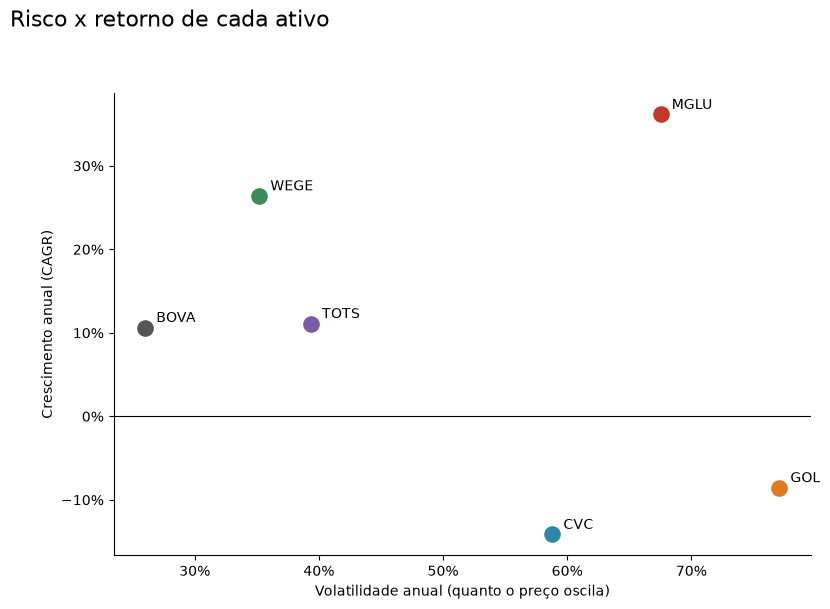

,Volatilidade anual,CAGR
GOL,77.1%,-8.6%
CVC,58.8%,-14.2%
WEGE,35.2%,26.4%
MGLU,67.5%,36.2%
TOTS,39.4%,11.1%
BOVA,26.0%,10.6%


In [17]:
risco_retorno = pd.DataFrame({
    'Volatilidade anual': volatilidade(precos),
    'CAGR': cagr(precos),
})

plt.figure(figsize=(9, 6))
for ativo, linha in risco_retorno.iterrows():
    plt.scatter(linha['Volatilidade anual'], linha['CAGR'], s=120, color=CORES[ativo])
    plt.annotate(ativo, (linha['Volatilidade anual'], linha['CAGR']), xytext=(8, 4), textcoords='offset points')
plt.axhline(0, color='black', lw=0.8)
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.xlabel('Volatilidade anual (quanto o preço oscila)')
plt.ylabel('Crescimento anual (CAGR)')
sns.despine()
plt.suptitle('Risco x retorno de cada ativo', fontsize=16, x=0.01, ha='left', y=1.02)
salvar('Risco x retorno')
plt.show()

risco_retorno.style.format('{:.1%}')

❌ **Falsa.** Mais oscilação **não** garantiu mais retorno:
- 🔎 A **GOL** foi o ativo mais volátil (**77%** ao ano) e teve retorno **negativo** (−8,6% ao ano).
- 🔎 A **WEGE**, com volatilidade moderada (**35%**), teve o 2º melhor resultado (+26,4% ao ano).
- 🔎 O **BOVA11** foi o menos volátil (**26%**) e rendeu praticamente o mesmo que a TOTS (39% de volatilidade).
- 💡 Risco alto significa **resultados mais extremos**, para cima ou para baixo, e não retorno garantido.

### 3.4. Resumo das Hipóteses

| # | Hipótese | Resultado | Evidência |
|---|---|---|---|
| H1 | MGLU foi a que mais valorizou | ✅ Verdadeira | +1.077% (R$ 1 → R$ 11,77) |
| H2 | CVC e GOL foram as mais afetadas pela pandemia | ✅ Verdadeira | 2020: CVC −53%, GOL −32% |
| H3 | MGLU subiu na pandemia e devolveu o ganho | ✅ Verdadeira | Pico de 118x em nov/2020, queda de 90% |
| H4 | A carteira superou o BOVA11 | ✅ Verdadeira | 19,9% x 10,6% ao ano, com muito mais risco |
| H5 | O resultado depende de uma única ação | ✅ Verdadeira | Sem MGLU, empata com o BOVA11 |
| H6 | Ações mais voláteis renderam mais | ❌ Falsa | GOL: maior volatilidade e retorno negativo |

## 4 - FEATURE ENGINEERING — (engenharia de atributos)

| Variável | Fórmula | Para que serve |
|---|---|---|
| **Preço normalizado** | preço do dia ÷ preço do 1º dia | Comparar ações com preços diferentes (todas começam em 1) |
| **Retorno simples diário** | preço de hoje ÷ preço de ontem − 1 | Variação percentual de um dia; base para medir oscilação (volatilidade) |
| **Retorno logarítmico diário** | ln(preço de hoje ÷ preço de ontem) | Os retornos log **podem ser somados** ao longo do tempo |

> 💡 **Simples x logarítmico, na prática:** se uma ação sobe 10% e depois cai 10%, o retorno simples "soma" 0%, mas o investidor **perdeu 1%** (100 → 110 → 99). Já os retornos log somam −1%, o valor correto. Por isso, para **acumular** retornos no tempo, o retorno logarítmico é o mais indicado.

In [18]:
retorno_simples = precos.pct_change().dropna()
retorno_log = np.log(precos / precos.shift(1)).dropna()

# Exemplo: sobe 10% e depois cai 10%
exemplo = pd.Series([100, 110, 99])
print(f'Soma dos retornos simples: {exemplo.pct_change().sum():+.2%}')
print(f'Soma dos retornos log:     {np.log(exemplo / exemplo.shift(1)).sum():+.2%}')
print(f'Variação real:             {exemplo.iloc[-1] / exemplo.iloc[0] - 1:+.2%}')

Soma dos retornos simples: +0.00%
Soma dos retornos log:     -1.01%
Variação real:             -1.00%


## 5 - EXPLORANDO AS CORRELAÇÕES

A correlação dos **retornos diários** mostra quais ações costumam subir e cair **juntas**. Para o investidor, isso indica o grau de **diversificação**: quanto menor a correlação entre as ações, mais uma ajuda a compensar a outra nos dias ruins.

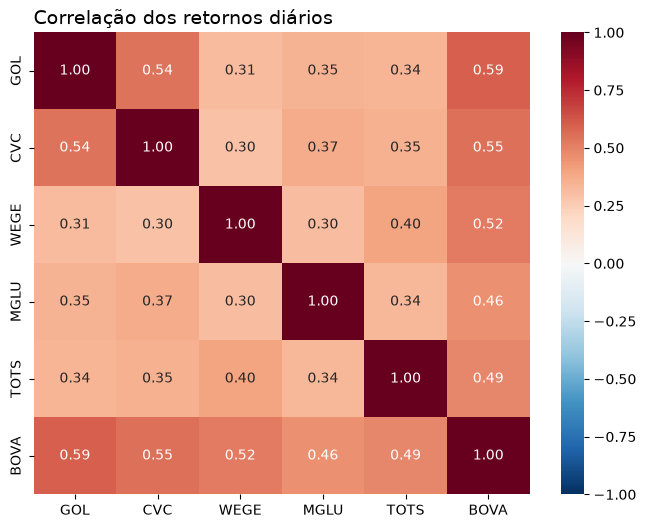

In [19]:
correlacao = retorno_simples.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlacao, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlação dos retornos diários', fontsize=14, loc='left')
salvar('Correlacao dos retornos')
plt.show()

📌 **Nota**
- 🔎 As correlações entre as 5 ações são **baixas a moderadas** (média de **0,36**). A maior é entre **GOL e CVC (0,54)**, as duas ligadas a viagens, que sofrem juntas com os mesmos eventos.
- 🔎 Todas as ações têm correlação de **0,46 a 0,59** com o BOVA11: em parte, elas acompanham o mercado.
- 💡 Correlação baixa é boa para **diversificação**, mas não protegeu a carteira em 2021–2022: o problema não foi a correlação, e sim o **peso** que a MGLU passou a ter depois de subir tanto (Fase 04, item 3).

# FASE 03: CÁLCULO DOS INDICADORES E MONTAGEM DA CARTEIRA

*(No roteiro de Machine Learning, esta é a fase de Modelagem. Aqui, o "modelo" é a forma de calcular o retorno de cada ação e da carteira.)*

## 1 - Leitura dos dados

In [20]:
print(f'Preços: {precos.shape} | Retornos diários: {retorno_simples.shape}')
retorno_simples.head()

Preços: (1988, 6) | Retornos diários: (1987, 6)


,GOL,CVC,WEGE,MGLU,TOTS,BOVA
Date,,,,,,
2015-01-05,-0.009340,-0.013158,0.006818,0.018792,-0.030726,-0.019890
2015-01-06,0.024242,-0.013333,-0.014834,-0.013175,-0.062536,0.005613
2015-01-07,-0.043392,-0.008784,-0.011457,0.033380,-0.007070,0.033705
2015-01-08,-0.019244,-0.035447,0.016887,-0.007752,0.023220,0.007477
2015-01-09,-0.015417,-0.010601,-0.004559,-0.033854,-0.010287,-0.020202


## 2 - Valores nulos

O primeiro dia não tem retorno (não existe "dia anterior"), então essa linha foi removida com `dropna()` ao criar os retornos.

In [21]:
print(f'Nulos nos retornos simples: {retorno_simples.isnull().sum().sum()} | nos retornos log: {retorno_log.isnull().sum().sum()}')

Nulos nos retornos simples: 0 | nos retornos log: 0


## 3 - Transformação

As transformações usadas (preço normalizado, retorno simples e retorno logarítmico) foram criadas na Fase 02, item 4.

## 4 - Pré-Processamento

### 4.1. Separação do conjunto de dados

> 🚫 **Não se aplica.** Separar treino e teste serve para medir se um modelo **prevê bem dados novos**. Aqui não há previsão: medimos o que **já aconteceu** em todo o período.

### 4.2. Balancear os dados

> 🚫 **Não se aplica.** Não há classes a balancear.

### 4.3. Seleção de Variáveis

| Escolha | Decisão | Motivo |
|---|---|---|
| **Preço usado** | **Close** na análise principal + **Adj Close** para medir os dividendos | Mantém a comparação com a versão original e mostra quanto os dividendos acrescentam |
| **Ativos da carteira** | GOL, CVC, WEGE, MGLU, TOTS | Escolhidos na versão original, de setores diferentes |
| **Referências (benchmarks)** | **BOVA11** e **CDI** | BOVA11: "quanto eu ganharia sem escolher ações". CDI: "quanto eu ganharia **sem risco**, na renda fixa" |

Quanto os **dividendos** mudam o retorno total de cada ativo?

In [22]:
dividendos = pd.DataFrame({
    'Sem dividendos (Close)': retorno_total(precos),
    'Com dividendos (Adj Close)': retorno_total(precos_ajustados),
})
dividendos['Diferença'] = dividendos['Com dividendos (Adj Close)'] - dividendos['Sem dividendos (Close)']
dividendos.style.format('{:+.1%}')

,Sem dividendos (Close),Com dividendos (Adj Close),Diferença
GOL,-51.0%,-51.0%,+0.0%
CVC,-70.5%,-62.6%,+7.9%
WEGE,+550.2%,+646.3%,+96.1%
MGLU,+1076.9%,+1145.2%,+68.3%
TOTS,+131.9%,+161.7%,+29.8%
BOVA,+124.2%,+124.2%,+0.0%


📌 **Nota**
- 🔎 Com dividendos, a **WEGE** passa de +550% para **+646%** (R$ 1 → R$ 7,46) e a **MGLU** de +1.077% para **+1.145%**. A **TOTS** ganha 30 pontos percentuais e até a **CVC** perde um pouco menos (−63% em vez de −70%).
- 🔎 O **BOVA11 não muda**: o fundo **reinveste** os dividendos das empresas do índice, em vez de distribuí-los, então o preço já os inclui.
- 🔎 A **GOL** não muda porque o preço ajustado dela não está mais disponível (ver item 1.2).
- ✅ **Decisão:** a análise principal continua com o *Close*, para comparar com a versão original, e a avaliação final (Fase 04) mostra a carteira **com** dividendos.

## 5 - Treinamento dos Algoritmos de Machine Learning

*(Adaptado: **cálculo das taxas de retorno**.)*

Existem três formas comuns de transformar 8 anos de preços em uma **taxa anual**:

| Método | Como calcula | Usado na versão original? |
|---|---|---|
| **Média aritmética anualizada** | média dos retornos simples diários × 246 pregões | ✅ Sim |
| **Média logarítmica anualizada** | média dos retornos log diários × 246 pregões | ✅ Sim |
| **CAGR** (crescimento anual composto) | (preço final ÷ preço inicial)^(1 / anos) − 1 | ❌ Não |

In [23]:
DIAS_UTEIS = 246  # número de pregões por ano usado na versão original

metodos = pd.DataFrame({
    'Retorno total': retorno_total(precos),
    'Média aritmética × 246 (v1)': retorno_simples.mean() * DIAS_UTEIS,
    'Média logarítmica × 246 (v1)': retorno_log.mean() * DIAS_UTEIS,
    'CAGR (v2)': cagr(precos),
})
metodos.style.format('{:+.1%}')

,Retorno total,Média aritmética × 246 (v1),Média logarítmica × 246 (v1),CAGR (v2)
GOL,-51.0%,+19.6%,-8.8%,-8.6%
CVC,-70.5%,+2.1%,-15.1%,-14.2%
WEGE,+550.2%,+29.3%,+23.2%,+26.4%
MGLU,+1076.9%,+52.3%,+30.5%,+36.2%
TOTS,+131.9%,+18.0%,+10.4%,+11.1%
BOVA,+124.2%,+13.3%,+10.0%,+10.6%


## 6 - Comparação do desempenho dos modelos

*(Adaptado: **qual forma de anualizar o retorno é a correta?**)*

📌 **Nota**
- 🔎 A **média aritmética × 246** (usada na versão original) **superestima** o retorno, e o erro cresce com a volatilidade:
  - a **GOL**, que **perdeu 51%**, aparece com **+19,6% ao ano**;
  - a **CVC**, que **perdeu 70%**, aparece com **+2,1% ao ano**.
- 🔎 A **média logarítmica × 246** fica próxima do CAGR (diferenças pequenas, porque o número de pregões por ano varia entre 246 e 254).
- 💡 **Por que a média aritmética erra?** Lembra do exemplo do item 4: subir 10% e cair 10% dá média 0%, mas o investidor **perde 1%**. Em ações que oscilam muito, esse efeito se acumula dia após dia.
- ✅ **Decisão:** usar o **CAGR**, que responde exatamente à pergunta do investidor: *"qual taxa fixa por ano levaria o meu dinheiro do valor inicial ao valor final?"*

## 7 - AJUSTE FINO DE HIPERPARÂMETROS

*(Adaptado: **os pesos da carteira**.)*

Na carteira, o "hiperparâmetro" é **quanto investir em cada ação**. Comparamos a carteira de **pesos iguais** (usada na versão original) com outras divisões simples:

| Carteira | Pesos |
|---|---|
| **Pesos iguais** | 20% em cada ação |
| **Sem as empresas de turismo e aviação** | 33% em WEGE, MGLU e TOTS |
| **Pesos iguais + rebalanceamento anual** | 20% em cada ação, e **no fim de cada ano** o dinheiro é redistribuído para voltar aos 20% |
| **Só as 2 melhores do período** | 50% WEGE e 50% MGLU (**só sabemos disso olhando para trás!**) |

Para comparar retorno **e** risco ao mesmo tempo, usamos o **Índice de Sharpe**:

> **Sharpe = (CAGR − CAGR do CDI) ÷ volatilidade**

Ele mede **quanto de retorno acima da renda fixa** o investimento entregou **para cada unidade de risco**. Quanto maior, melhor: um Sharpe de 0,5 significa que cada 1% de oscilação foi "pago" com 0,5% de retorno extra sobre o CDI.

In [24]:
# nome: (pesos, rebalancear todo ano?)
carteiras = {
    'Pesos iguais (5 ações)': ({acao: 0.2 for acao in ACOES}, False),
    'Pesos iguais + rebalanceamento anual': ({acao: 0.2 for acao in ACOES}, True),
    'Sem turismo/aviação (WEGE, MGLU, TOTS)': ({'WEGE': 1, 'MGLU': 1, 'TOTS': 1}, False),
    'Só as 2 melhores (WEGE, MGLU)': ({'WEGE': 1, 'MGLU': 1}, False),
    'BOVA11 (referência)': ({'BOVA': 1}, False),
}

linhas = {}
for nome, (pesos, rebalancear) in carteiras.items():
    valor = simular_carteira(precos, pesos, rebalancear=rebalancear)
    linhas[nome] = {'Valor final de R$ 10.000': valor.iloc[-1], 'CAGR': cagr(valor),
                    'Volatilidade anual': volatilidade(valor), 'Maior queda': maior_queda(valor),
                    'Sharpe': indice_sharpe(valor, cdi)}

resultado_carteiras = pd.DataFrame(linhas).T
resultado_carteiras.style.format({'Valor final de R$ 10.000': 'R$ {:,.0f}', 'CAGR': '{:.1%}',
                                  'Volatilidade anual': '{:.1%}', 'Maior queda': '{:.1%}', 'Sharpe': '{:.2f}'})

,Valor final de R$ 10.000,CAGR,Volatilidade anual,Maior queda,Sharpe
Pesos iguais (5 ações),"R$ 42,750",19.9%,45.5%,-87.2%,0.25
Pesos iguais + rebalanceamento anual,"R$ 62,147",25.7%,37.6%,-62.3%,0.46
"Sem turismo/aviação (WEGE, MGLU, TOTS)","R$ 68,633",27.3%,48.2%,-87.8%,0.39
"Só as 2 melhores (WEGE, MGLU)","R$ 91,354",31.9%,51.3%,-89.1%,0.45
BOVA11 (referência),"R$ 22,419",10.6%,26.0%,-46.9%,0.08


📌 **Nota**

| Carteira | R$ 10.000 viraram | CAGR | Volatilidade | Maior queda | Sharpe |
|---|---|---|---|---|---|
| Pesos iguais (comprar e manter) | R$ 42.750 | 19,9% | 45,5% | −87,2% | 0,25 |
| **Pesos iguais + rebalanceamento anual** | **R$ 62.147** | **25,7%** | **37,6%** | **−62,3%** | **0,46** |
| Sem turismo/aviação | R$ 68.633 | 27,3% | 48,2% | −87,8% | 0,39 |
| Só as 2 melhores | R$ 91.354 | 31,9% | 51,3% | −89,1% | 0,45 |
| BOVA11 | R$ 22.419 | 10,6% | 26,0% | −46,9% | 0,08 |

- 🔎 **Rebalancear todo ano** rendeu **45% a mais** que comprar e manter (R$ 62 mil x R$ 43 mil) **e** com menos risco: a maior queda caiu de 87% para 62%. É a melhor relação retorno/risco **entre as carteiras que não usam informação do futuro** (Sharpe de 0,46).
- 🔎 "Sem turismo/aviação" e "só as 2 melhores" rendem mais, mas só são possíveis **olhando para trás** (*viés de retrospectiva*): em 2015, ninguém sabia quais ações iriam disparar.
- 🔎 O **BOVA11** tem Sharpe de apenas **0,08**: no período, ele quase não compensou o risco em relação à renda fixa.

#### Comprar e manter x rebalancear todo ano

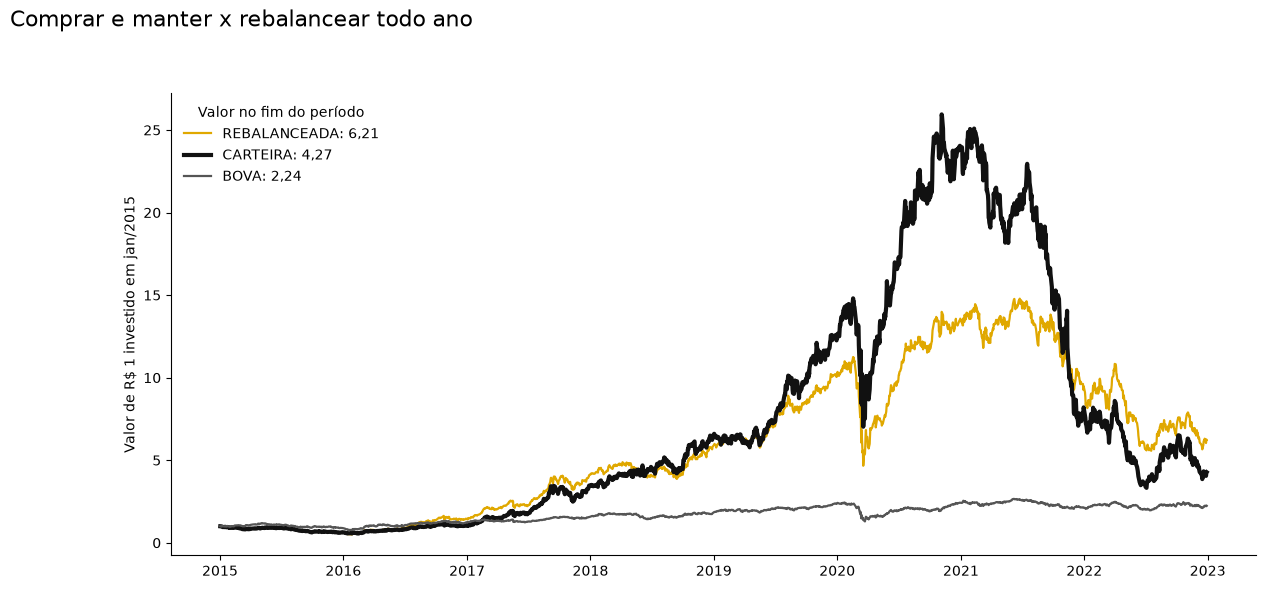

In [25]:
rebalanceamento = pd.DataFrame({
    'CARTEIRA': simular_carteira(precos, pesos_iguais, valor_inicial=1),
    'REBALANCEADA': simular_carteira(precos, pesos_iguais, valor_inicial=1, rebalancear=True),
    'BOVA': simular_carteira(precos, {'BOVA': 1}, valor_inicial=1),
})
plot_linhas(rebalanceamento, 'Comprar e manter x rebalancear todo ano', 'Rebalanceamento',
            ylabel='Valor de R$ 1 investido em jan/2015')

📌 **Nota**
- 🔎 Até 2019 as duas estratégias andam juntas. Na alta da MGLU (2020), a carteira **sem** rebalanceamento sobe mais, porque a MGLU passou a ocupar quase toda a carteira.
- 🔎 Na queda (2021–2022), é exatamente essa concentração que derruba a carteira. A rebalanceada **vendia parte do que tinha subido** no fim de cada ano e chegou a 2022 com **R$ 6,21** para cada R$ 1, contra **R$ 4,27**.
- 💡 **Em uma frase:** rebalancear é **realizar parte do lucro** do que subiu e **reforçar** o que ficou para trás, mantendo a carteira diversificada.

### 7.3. Modelo final

A carteira analisada é a de **pesos iguais (20% em cada uma das 5 ações)**, comprada no início de 2015 e mantida até o fim de 2022, sem rebalanceamento. É a carteira da versão original e a mais "honesta": não usa informação do futuro para escolher os pesos. A versão **rebalanceada** é discutida como alternativa nos insights.

## 8 - Otimização de limiar e calibração

> 🚫 **Não se aplica (itens 8.1 a 8.4).** Limiar e calibração são usados para transformar probabilidades de um modelo de classificação em decisões. Este projeto não tem um modelo que gere probabilidades.

# FASE 04: AVALIAÇÃO

Avaliamos a carteira de pesos iguais contra o **BOVA11** (mercado de ações) e o **CDI** (renda fixa, sem risco) e investigamos **de onde veio o resultado**.

## 1 - Avaliando a Máquina Preditiva

*(Adaptado: **avaliação da carteira x BOVA11 x CDI**.)*

,Valor final de R$ 10.000,CAGR,Volatilidade anual,Maior queda,Sharpe
Carteira (sem dividendos),"R$ 42,750",19.9%,45.5%,-87.2%,0.25
Carteira (com dividendos),"R$ 46,792",21.3%,45.2%,-86.8%,0.28
BOVA11,"R$ 22,419",10.6%,26.0%,-46.9%,0.08
CDI,"R$ 19,280",8.6%,0.3%,0.0%,0.00


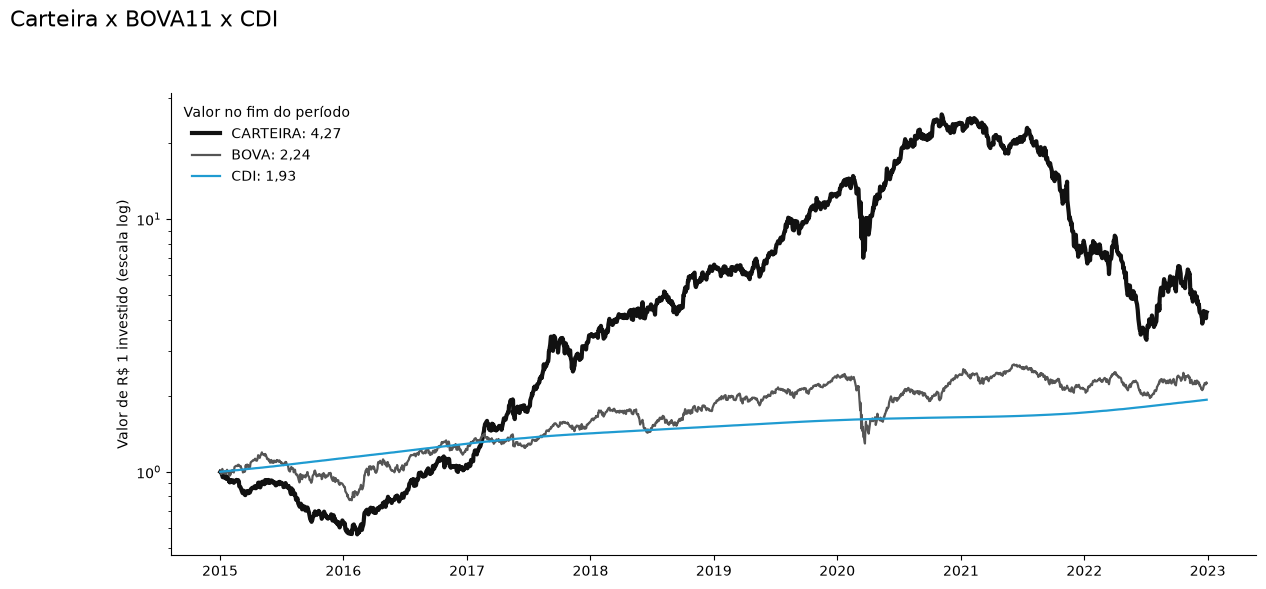

In [26]:
carteira = simular_carteira(precos, pesos_iguais, valor_inicial=10_000)
carteira_com_dividendos = simular_carteira(precos_ajustados, pesos_iguais, valor_inicial=10_000)
bova = simular_carteira(precos, {'BOVA': 1}, valor_inicial=10_000)
renda_fixa = cdi * 10_000

investimentos = {'Carteira (sem dividendos)': carteira, 'Carteira (com dividendos)': carteira_com_dividendos,
                 'BOVA11': bova, 'CDI': renda_fixa}

avaliacao = pd.DataFrame({
    nome: {'Valor final de R$ 10.000': valor.iloc[-1], 'CAGR': cagr(valor), 'Volatilidade anual': volatilidade(valor),
           'Maior queda': maior_queda(valor), 'Sharpe': indice_sharpe(valor, cdi)}
    for nome, valor in investimentos.items()
}).T
display(avaliacao.style.format({'Valor final de R$ 10.000': 'R$ {:,.0f}', 'CAGR': '{:.1%}',
                                'Volatilidade anual': '{:.1%}', 'Maior queda': '{:.1%}', 'Sharpe': '{:.2f}'}))

plot_linhas(pd.DataFrame({'CARTEIRA': carteira, 'BOVA': bova, 'CDI': renda_fixa}) / 10_000,
            'Carteira x BOVA11 x CDI', 'Carteira x BOVA x CDI', ylabel='Valor de R$ 1 investido (escala log)', log=True)

📌 **Nota**

| | Carteira (sem dividendos) | Carteira (com dividendos) | BOVA11 | CDI |
|---|---|---|---|---|
| **R$ 10.000 viraram** | R$ 42.750 | **R$ 46.792** | R$ 22.419 | R$ 19.280 |
| **CAGR** | 19,9% | **21,3%** | 10,6% | 8,6% |
| **Volatilidade anual** | 45,5% | 45,2% | 26,0% | 0,3% |
| **Maior queda** | −87,2% | −86,8% | −46,9% | 0% |
| **Sharpe** | 0,25 | **0,28** | 0,08 | – |

- ✅ **A carteira rendeu mais que as duas referências:** com dividendos, R$ 10.000 viraram **R$ 46.792**, mais que o dobro do BOVA11 e do CDI.
- ⚠️ **Mas com risco muito maior:** a carteira chegou a perder **87%** entre nov/2020 (R$ 259 mil) e jul/2022 (R$ 33 mil). O BOVA11, no pior momento (março de 2020), perdeu 47%. O CDI nunca caiu.
- 🔎 **O CDI foi um concorrente forte:** rendeu **8,6% ao ano sem nenhuma oscilação**, apenas 2 pontos abaixo do BOVA11. Por isso o Sharpe do BOVA11 é tão baixo (0,08).

### 1.1. A carteira teria vencido em qualquer momento? (janelas de 3 anos)

O resultado acima depende de ter começado **exatamente em jan/2015**. Para testar a consistência, calculamos o CAGR dos **3 anos seguintes** para **cada data de início possível** e comparamos carteira, BOVA11 e CDI.

Janelas de 3 anos analisadas: 1232 (inícios entre 01/2015 e 12/2019)
A carteira superou o BOVA11 em 82% das janelas
A carteira superou o CDI em    84% das janelas
O BOVA11 superou o CDI em      82% das janelas


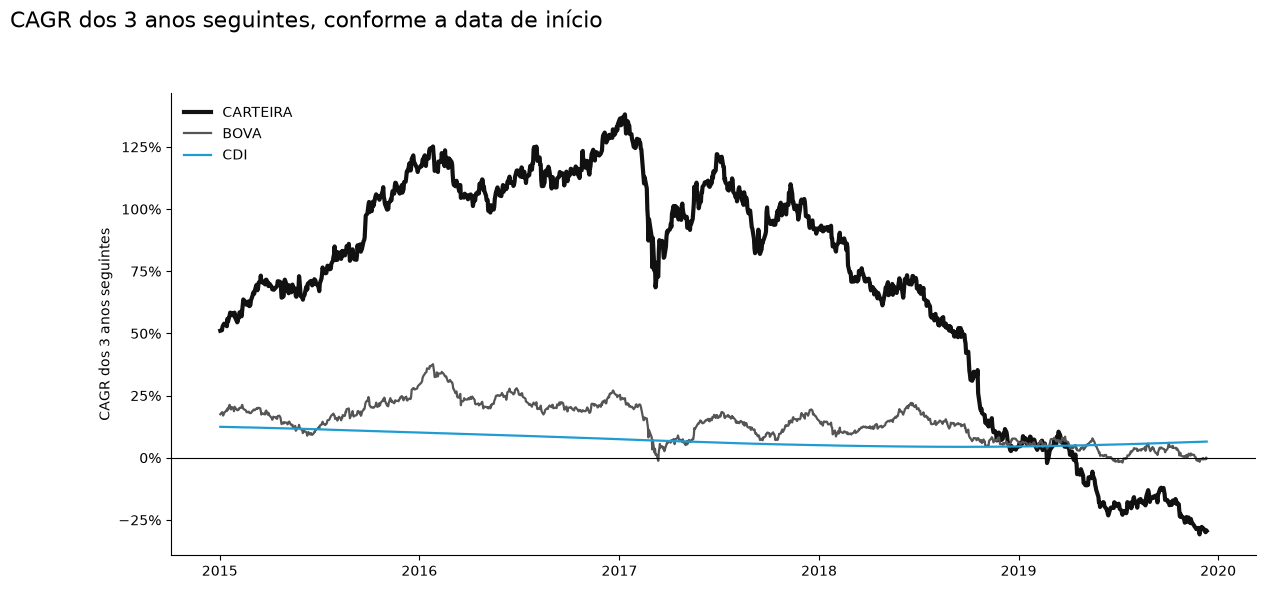

In [27]:
janelas = pd.DataFrame({
    'CARTEIRA': cagr_janelas(carteira, anos=3),
    'BOVA': cagr_janelas(bova, anos=3),
    'CDI': cagr_janelas(cdi, anos=3),
}).dropna()

print(f'Janelas de 3 anos analisadas: {len(janelas)} (inícios entre {janelas.index[0]:%m/%Y} e {janelas.index[-1]:%m/%Y})')
print(f"A carteira superou o BOVA11 em {(janelas['CARTEIRA'] > janelas['BOVA']).mean():.0%} das janelas")
print(f"A carteira superou o CDI em    {(janelas['CARTEIRA'] > janelas['CDI']).mean():.0%} das janelas")
print(f"O BOVA11 superou o CDI em      {(janelas['BOVA'] > janelas['CDI']).mean():.0%} das janelas")

plot_linhas(janelas, 'CAGR dos 3 anos seguintes, conforme a data de início', 'Janelas de 3 anos',
            ylabel='CAGR dos 3 anos seguintes', percentual=True)

📌 **Nota**
- 🔎 Foram analisadas **1.232 janelas** de 3 anos (inícios entre jan/2015 e dez/2019). A carteira superou o BOVA11 em **82%** delas e o CDI em **84%**.
- 🔎 Mas o resultado depende muito **de quando se começa**: para inícios até **nov/2018**, a carteira venceu o BOVA11 em **99%** das janelas. A partir de **jun/2019**, perdeu em **100%** delas. Quem começou em **nov/2019** perdeu **31% ao ano** nos 3 anos seguintes.
- 💡 O "sucesso" da carteira depende de ter entrado **antes** da alta de 2020. Começando depois, ela pegou só a queda.

## 2 - Previsto x observado

*(Adaptado: **o retorno anual "estimado" pela versão original x o crescimento que realmente aconteceu**.)*

Se o retorno anual estiver correto, aplicar essa taxa ano após ano deveria levar do preço inicial ao preço final. Vamos testar:

In [28]:
anos = anos_no_periodo(precos)

previsto_observado = pd.DataFrame({
    'Taxa anual da v1 (média × 246)': metodos['Média aritmética × 246 (v1)'],
    'R$ 1 viraria (com a taxa da v1)': (1 + metodos['Média aritmética × 246 (v1)']) ** anos,
    'R$ 1 virou de verdade': precos.iloc[-1] / precos.iloc[0],
    'Taxa anual correta (CAGR)': metodos['CAGR (v2)'],
})
previsto_observado.style.format({'Taxa anual da v1 (média × 246)': '{:+.1%}', 'Taxa anual correta (CAGR)': '{:+.1%}',
                                 'R$ 1 viraria (com a taxa da v1)': 'R$ {:.2f}', 'R$ 1 virou de verdade': 'R$ {:.2f}'})

,Taxa anual da v1 (média × 246),R$ 1 viraria (com a taxa da v1),R$ 1 virou de verdade,Taxa anual correta (CAGR)
GOL,+19.6%,R$ 4.17,R$ 0.49,-8.6%
CVC,+2.1%,R$ 1.18,R$ 0.30,-14.2%
WEGE,+29.3%,R$ 7.77,R$ 6.50,+26.4%
MGLU,+52.3%,R$ 28.88,R$ 11.77,+36.2%
TOTS,+18.0%,R$ 3.75,R$ 2.32,+11.1%
BOVA,+13.3%,R$ 2.72,R$ 2.24,+10.6%


📌 **Nota**
- 🔎 Se a taxa anual da versão original estivesse correta, R$ 1 na GOL teria virado **R$ 4,17**, mas virou **R$ 0,49**. Na MGLU, seriam **R$ 28,88**, contra **R$ 11,77** de verdade.
- 🔎 A taxa da v1 **superestima todos os ativos**, até o BOVA11 (R$ 2,72 x R$ 2,24), e erra mais nos mais voláteis.
- ✅ O **CAGR**, por definição, leva exatamente ao valor final real. É por isso que ele é o indicador usado em fundos e relatórios de investimento.

## 3 - Quais variáveis mais influenciam o modelo?

*(Adaptado: **quanto cada ação contribuiu para o valor final da carteira**.)*

,Investido,Valor final,Lucro/prejuízo,% do valor final da carteira
MGLU,"R$ 2,000","R$ 23,538","R$ +21,538",55.1%
WEGE,"R$ 2,000","R$ 13,003","R$ +11,003",30.4%
TOTS,"R$ 2,000","R$ 4,638","R$ +2,638",10.8%
GOL,"R$ 2,000",R$ 979,"R$ -1,021",2.3%
CVC,"R$ 2,000",R$ 591,"R$ -1,409",1.4%


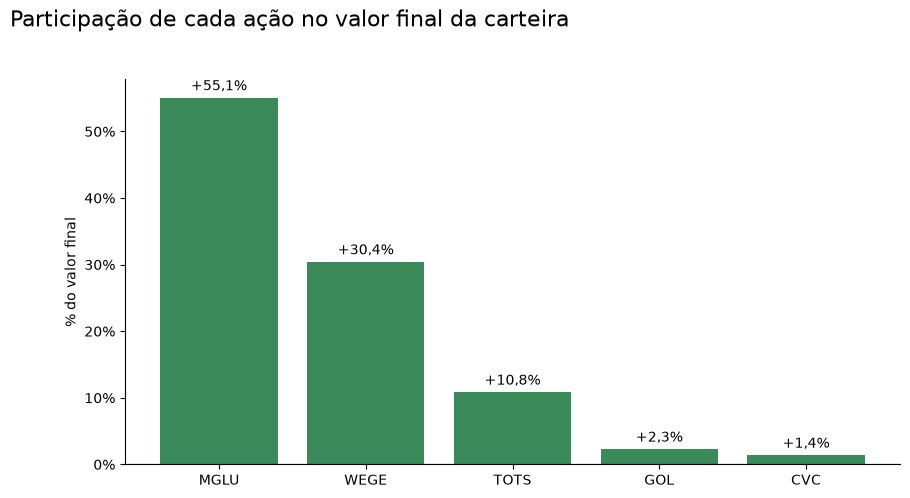

In [29]:
valor_por_acao = (precos[ACOES] / precos[ACOES].iloc[0] * 2_000).iloc[-1]  # R$ 2.000 em cada ação
contribuicao = pd.DataFrame({
    'Investido': 2_000,
    'Valor final': valor_por_acao,
    'Lucro/prejuízo': valor_por_acao - 2_000,
    '% do valor final da carteira': valor_por_acao / valor_por_acao.sum(),
}).sort_values('Valor final', ascending=False)
display(contribuicao.style.format({'Investido': 'R$ {:,.0f}', 'Valor final': 'R$ {:,.0f}',
                                   'Lucro/prejuízo': 'R$ {:+,.0f}', '% do valor final da carteira': '{:.1%}'}))

plot_barras_retorno(contribuicao['% do valor final da carteira'], 'Participação de cada ação no valor final da carteira',
                    'Contribuicao por acao', ylabel='% do valor final')

📌 **Nota**
- 🔎 Dos R$ 42.750 finais, **R$ 23.538 (55%) vieram da MGLU** e **R$ 13.003 (30%) da WEGE**: juntas, **85% do valor final**.
- 🔎 GOL e CVC terminaram com **R$ 979** e **R$ 591**, um prejuízo de **R$ 2.430** dos R$ 4.000 investidos nelas.
- 💡 Como a carteira não é rebalanceada, a ação que mais sobe passa a **dominar** a carteira. Em 2020, a MGLU chegou a representar a maior parte do valor, e por isso a queda dela em 2021–2022 derrubou a carteira inteira.

# FASE 05: IMPLANTAÇÃO

## 1 - Salvando o modelo

*(Adaptado: **salvando a tabela de indicadores**.)* Não há modelo treinado para salvar; a entrega é uma tabela com os indicadores de cada ativo e da carteira, que pode ser usada em planilhas ou no Power BI.

In [30]:
indicadores = pd.DataFrame({
    'Retorno total': retorno_total(precos),
    'CAGR': cagr(precos),
    'Volatilidade anual': volatilidade(precos),
    'Maior queda': maior_queda(precos),
    'Sharpe': indice_sharpe(precos, cdi),
})
for nome, valor in {'CARTEIRA': carteira, 'CDI': cdi}.items():
    indicadores.loc[nome] = [retorno_total(valor), cagr(valor), volatilidade(valor), maior_queda(valor),
                             indice_sharpe(valor, cdi)]

indicadores.round(4).to_csv('../Datasets/indicadores_desempenho.csv', index_label='Ativo')
indicadores.style.format('{:+.1%}', subset=['Retorno total', 'CAGR', 'Volatilidade anual', 'Maior queda'])     .format('{:.2f}', subset=['Sharpe'])

,Retorno total,CAGR,Volatilidade anual,Maior queda,Sharpe
GOL,-51.0%,-8.6%,+77.1%,-92.4%,-0.22
CVC,-70.5%,-14.2%,+58.8%,-94.4%,-0.39
WEGE,+550.2%,+26.4%,+35.2%,-50.5%,0.51
MGLU,+1076.9%,+36.2%,+67.5%,-92.2%,0.41
TOTS,+131.9%,+11.1%,+39.4%,-49.7%,0.06
BOVA,+124.2%,+10.6%,+26.0%,-46.9%,0.08
CARTEIRA,+327.5%,+19.9%,+45.5%,-87.2%,0.25
CDI,+92.8%,+8.6%,+0.3%,+0.0%,0.00


## 2 - Aplicando uma simulação

Quanto valeriam **R$ 10.000** investidos em jan/2015 em cada ação, na carteira, no BOVA11 e no CDI?

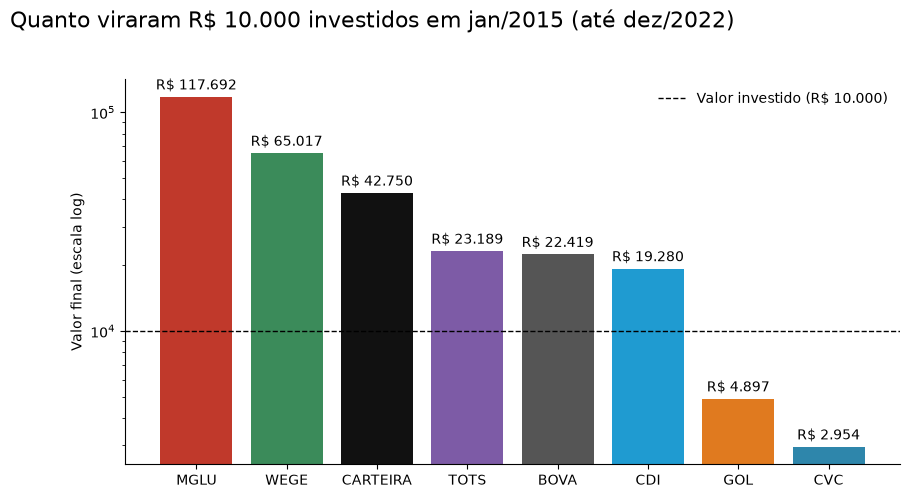

In [31]:
simulacao = pd.Series({ativo: simular_carteira(precos, {ativo: 1}).iloc[-1] for ativo in precos.columns})
simulacao['CARTEIRA'] = carteira.iloc[-1]
simulacao['CDI'] = renda_fixa.iloc[-1]
simulacao = simulacao.sort_values(ascending=False)

plt.figure(figsize=(10, 5))
barras = plt.bar(simulacao.index, simulacao.values, color=[CORES[a] for a in simulacao.index])
plt.bar_label(barras, labels=[f'R$ {v:,.0f}'.replace(',', '.') for v in simulacao.values], padding=3)
plt.axhline(10_000, color='black', ls='--', lw=1, label='Valor investido (R$ 10.000)')
plt.yscale('log')
plt.ylabel('Valor final (escala log)')
plt.legend(frameon=False)
sns.despine()
plt.suptitle('Quanto viraram R$ 10.000 investidos em jan/2015 (até dez/2022)', fontsize=16, x=0.01, ha='left', y=1.02)
salvar('Simulacao R$ 10 mil')
plt.show()

📌 **Nota – R$ 10.000 investidos em jan/2015 viraram, em dez/2022 (sem dividendos):**

| Ativo | Valor final |
|---|---|
| MGLU | R$ 117.692 |
| WEGE | R$ 65.017 |
| **CARTEIRA (5 ações)** | **R$ 42.750** |
| TOTS | R$ 23.189 |
| **BOVA11** | **R$ 22.419** |
| **CDI** | **R$ 19.280** |
| GOL | R$ 4.897 |
| CVC | R$ 2.954 |

> ⚠️ Valores sem custos (corretagem, impostos e taxa de administração). Rentabilidade passada não garante rentabilidade futura.

# 💡 INSIGHTS

1. **A carteira rendeu mais que o índice e a renda fixa:** R$ 10.000 viraram **R$ 42.750** (R$ 46.792 com dividendos), contra R$ 22.419 no BOVA11 e R$ 19.280 no CDI.
2. **O resultado veio de duas ações:** MGLU e WEGE respondem por **85%** do valor final. Sem a MGLU, a carteira empata com o BOVA11.
3. **Rebalancear todo ano teria sido melhor em retorno e em risco:** R$ 62.147, com a maior queda reduzida de 87% para 62%. Manter a carteira diversificada protegeu contra a queda da MGLU.
4. **O momento de entrada importa:** em janelas de 3 anos, a carteira venceu o BOVA11 em 99% dos inícios até nov/2018 e perdeu em 100% dos inícios a partir de jun/2019.
5. **O CDI foi difícil de bater com segurança:** 8,6% ao ano sem oscilação. O BOVA11 entregou só 2 pontos a mais, com quedas de até 47% (Sharpe de 0,08).
6. **A forma de calcular importa:** a média dos retornos diários (versão original) mostrava a GOL com +19,6% ao ano, quando ela perdeu metade do valor. O **CAGR** é o indicador correto.
7. **Volatilidade não é sinônimo de retorno:** a ação mais volátil (GOL) teve Sharpe negativo; a WEGE, com volatilidade moderada, teve o **melhor Sharpe** (0,51).

# 🚀 PRÓXIMOS PASSOS

1. **Aprofundar o risco** (variância, covariância e correlação entre as ações), feito na **[parte 2](https://github.com/RafaelSilva89/Calculo_do_risco_das_acoes-Financas_parte_2)** deste estudo.
2. **Considerar custos**: corretagem, impostos sobre o lucro e a taxa de administração do BOVA11.
3. **Atualizar os dados** até a data atual (`ATUALIZAR_DADOS = True`), substituindo o ticker da GOL, e verificar se as conclusões se mantêm.
4. **Testar outras regras de carteira**, como pesos pelo risco (ações mais voláteis com peso menor).
5. **Publicar o app** no Streamlit Community Cloud e gravar um GIF para o README.

# 🖥️ Interface com Streamlit

Para que qualquer pessoa simule a própria carteira **sem abrir o notebook**, criamos um app em **Streamlit**:
1. O usuário escolhe o **valor investido**, o **período** e o **peso de cada ação**.
2. Pode escolher **incluir dividendos** e **rebalancear todo ano**.
3. O app mostra o **valor final**, o **CAGR**, o **Índice de Sharpe** e a evolução da carteira comparada ao **BOVA11** e ao **CDI**, além do resultado de cada ação.

A célula abaixo grava o arquivo `app.py` na raiz do projeto. Para executar (a partir da raiz):

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [32]:
%%writefile ../app.py
from pathlib import Path

import pandas as pd
import streamlit as st

from src.financas import EMPRESAS, carregar_cdi, carregar_precos, cagr, indice_sharpe, maior_queda, simular_carteira

st.set_page_config(page_title="Simulador de Carteira 📈", page_icon="📈", layout="wide")
st.title("📈 Simulador de Carteira de Ações")
st.markdown("Monte uma carteira com as ações do estudo e compare com o **BOVA11** (Ibovespa) e o **CDI** (renda fixa).")

PASTA_DADOS = Path(__file__).parent / "Datasets"


### Carregamento dos dados
@st.cache_data
def carregar(com_dividendos):
    arquivo = "acoes_ajustado.csv" if com_dividendos else "acoes.csv"
    precos = carregar_precos(PASTA_DADOS / arquivo)
    return precos, carregar_cdi(PASTA_DADOS / "cdi.csv", precos.index)


def formatar_reais(valor):
    return f"R$ {valor:,.0f}".replace(",", ".")


### Parâmetros da simulação
with st.sidebar:
    st.header("⚙️ Simulação")
    valor_inicial = st.number_input("Valor investido (R$)", 1_000, 1_000_000, 10_000, step=1_000)
    com_dividendos = st.checkbox("Incluir dividendos (preço ajustado)", value=False)
    rebalancear = st.checkbox("Rebalancear todo ano (voltar aos pesos escolhidos)", value=False)

    precos, cdi = carregar(com_dividendos)
    inicio, fim = st.slider("Período", min_value=precos.index[0].date(), max_value=precos.index[-1].date(),
                            value=(precos.index[0].date(), precos.index[-1].date()), format="MM/YYYY")

    st.header("⚖️ Pesos da carteira (%)")
    acoes = [a for a in precos.columns if a != "BOVA"]
    pesos = {acao: st.slider(f"{acao} – {EMPRESAS[acao].split(' (')[0]}", 0, 100, 20, step=5) for acao in acoes}

if sum(pesos.values()) == 0:
    st.warning("Defina o peso de pelo menos uma ação.")
    st.stop()

periodo = precos.loc[str(inicio):str(fim)]
if len(periodo) < 2:
    st.warning("Escolha um período maior.")
    st.stop()

### Simulação
carteira = simular_carteira(periodo, pesos, valor_inicial, rebalancear=rebalancear)
bova = simular_carteira(periodo, {"BOVA": 1}, valor_inicial)
cdi_periodo = cdi.loc[periodo.index]
renda_fixa = cdi_periodo / cdi_periodo.iloc[0] * valor_inicial

col1, col2, col3, col4 = st.columns(4)
col1.metric("Minha carteira", formatar_reais(carteira.iloc[-1]), f"{carteira.iloc[-1] / valor_inicial - 1:+.1%}")
col2.metric("BOVA11 (Ibovespa)", formatar_reais(bova.iloc[-1]), f"{bova.iloc[-1] / valor_inicial - 1:+.1%}")
col3.metric("CDI (renda fixa)", formatar_reais(renda_fixa.iloc[-1]), f"{renda_fixa.iloc[-1] / valor_inicial - 1:+.1%}")
col4.metric("Crescimento anual (CAGR)", f"{cagr(carteira):.1%}",
            f"{(cagr(carteira) - cagr(bova)) * 100:+.1f} p.p. vs BOVA11")

st.markdown("#### Evolução do valor investido")
st.line_chart(pd.DataFrame({"Minha carteira": carteira, "BOVA11 (Ibovespa)": bova, "CDI (renda fixa)": renda_fixa}),
              y_label="R$")

st.markdown(f"**Índice de Sharpe** (retorno acima do CDI por unidade de risco): "
            f"carteira **{indice_sharpe(carteira, cdi_periodo):.2f}** · BOVA11 **{indice_sharpe(bova, cdi_periodo):.2f}** "
            f"· quanto maior, melhor. Maior queda da carteira no período: **{maior_queda(carteira):.1%}**.")

### Detalhe por ação
st.markdown("#### Resultado de cada ação no período")
pesos_validos = {a: p for a, p in pesos.items() if p > 0}
acoes_validas = list(pesos_validos)
detalhe = pd.DataFrame({
    "Peso": pd.Series(pesos_validos) / sum(pesos_validos.values()),
    "Retorno total": periodo[acoes_validas].iloc[-1] / periodo[acoes_validas].iloc[0] - 1,
    "CAGR": cagr(periodo[acoes_validas]),
    "Maior queda": maior_queda(periodo[acoes_validas]),
})
st.dataframe(detalhe.style.format("{:.1%}"), width="stretch")
st.caption("Sem custos de corretagem, impostos e taxa de administração. Com dividendos, a GOL usa o preço sem ajuste "
           "(ticker indisponível no Yahoo Finance). Rentabilidade passada não garante rentabilidade futura.")

Overwriting ../app.py
